<div align="center">

<img src="isel.png" width="350">


<h2>Instituto Superior de Engenharia de Lisboa</h2>

<h3>Departamento de Engenharia Informática</h3>

<br>

<h2>Processamento de Imagem e Visão</h2>

<h3>1.º Trabalho de Laboratório</h3>

<br><br>

<p>Telma Cardoso — A52302</p>
<p>Gonçalo Proença — A52456</p>

<br>

<p>Docente: Pedro Mendes Jorge</p>

<br><br>

<p>Ano letivo 2026/2027</p>

</div>


## 1. Introdução ##
O processamento de imagem e a visão por computador são áreas da informática que permitem analisar imagens digitais e extrair informação relevante de forma automática. Estas técnicas têm diversas aplicações, nomeadamente na deteção, identificação, contagem e classificação de objetos, contribuindo para o desenvolvimento de sistemas capazes de interpretar informação visual.
O presente trabalho laboratorial, desenvolvido no âmbito da unidade curricular de Processamento de Imagem e Visão, tem como principal objetivo implementar um algoritmo de visão por computador capaz de identificar, contar e classificar peças de Lego retangulares, de acordo com as suas dimensões. O sistema deverá distinguir peças dos tipos 2×2, 2×4, 2×6 e 2×8, presentes em imagens captadas por uma câmara, sobre uma superfície homogénea e clara.
Para a implementação da solução, será utilizada a linguagem de programação Python, em conjunto com a biblioteca OpenCV (Open Source Computer Vision Library), que disponibiliza diversas ferramentas para o processamento e a análise de imagens digitais. O desenvolvimento do algoritmo poderá envolver etapas como a binarização, o melhoramento da imagem, a extração de componentes conexos, a determinação de propriedades geométricas e a classificação dos objetos detetados.
Um dos principais desafios consiste em garantir que o algoritmo apresenta resultados fiáveis perante diferentes condições visuais, nomeadamente a presença de sombras, de outras peças de Lego na imagem e o eventual contacto entre peças. Assim, pretende-se desenvolver uma solução capaz de analisar as imagens de entrada e apresentar automaticamente a quantidade de peças identificadas em cada categoria.
Por fim, o desempenho do algoritmo será avaliado através de um conjunto de imagens de teste diferentes das utilizadas durante o desenvolvimento, permitindo analisar a sua capacidade de contagem e classificação nas condições previstas no enunciado.




## 2. Objetivo geral

O principal objetivo deste trabalho consiste no desenvolvimento de um algoritmo de visão por computador capaz de contar e classificar automaticamente peças de Lego retangulares, presentes numa imagem captada por uma câmara. O sistema deverá identificar as peças de acordo com as suas dimensões, nomeadamente 2×2, 2×4, 2×6 e 2×8, utilizando a linguagem Python e a biblioteca OpenCV.

## 2.1. Objetivos específicos

Para alcançar o objetivo geral, foram definidos os seguintes objetivos específicos:

- Explorar as funcionalidades da biblioteca OpenCV para o processamento e a análise de imagens digitais.
- Implementar técnicas de binarização e melhoramento de imagem para facilitar a identificação das peças.
- Detetar e extrair os objetos presentes nas imagens através da identificação de contornos ou componentes conexos.
- Analisar as propriedades geométricas dos objetos detetados, de forma a distinguir as diferentes dimensões das peças de Lego.
- Desenvolver um método de classificação que permita contabilizar separadamente as peças dos tipos 2×2, 2×4, 2×6 e 2×8.
- Procurar garantir a robustez do algoritmo perante a presença de sombras, de outras peças no campo de visão e de peças em contacto.
- Avaliar o desempenho da solução através de imagens de teste diferentes das utilizadas durante o desenvolvimento.


In [1]:
# (1) Ver técnicas para binarizar as imagens, para isso colocar em grayscale passar um filtro de gaussian Blur e aplicar threshold(segurar limiar).
# (2) Aplicar as técnicas de abertura e fecho do capitulo3, página 15.
# (3) Escolher o algoritmos que identifca cada região a branco. Ver o algoritmo que pega na imagem, percorre a ilha e tenta identifcar a parte branca portanto é detecção de ilhas, descarta-se as ilhas que não fazem parte tipo os circulos.


## 3. Análise das imagens e definição do problema ##

#### 3.1 Condições de aquisição e observação das imagens ####

  Com base nas 14 imagens disponibilizadas para o desenvolvimento do projeto, observa-se que todas têm fundo azul, embora não uniforme: há zonas mais claras e mais escuras, e o tom varia ligeiramente de imagem para imagem. Note-se que o enunciado refere uma mesa "clara", mas nas imagens o fundo é azul.

Os objetos presentes são de vários tipos: peças retangulares (quadradas, as 2x2, e alongadas, as 2x4, 2x6 e 2x8), peças em forma de meia-lua, peças curvas, peças com encaixe e bonecos. As cores das peças variam bastante: amarelo, laranja claro e escuro, castanho claro, vermelho, verde, verde-azulado, branco e cinzento.

As imagens foram adquiridas com a câmara por cima da mesa, a olhar para baixo, com o plano do sensor paralelo ao plano da mesa. Esta montagem tem uma consequência importante. Pelo modelo pin-hole (Cap. 2, slides 12 e 15), a ampliação é m = −f'/z, onde z é a distância à câmara. Como a mesa é paralela ao sensor, todos os pontos da mesa estão praticamente à mesma distância z, por isso não há efeito de perspetiva: a mesma peça tem o mesmo tamanho em pixéis em qualquer posição da imagem, e os retângulos continuam a aparecer como retângulos. Se a câmara estivesse inclinada, as peças mais afastadas pareceriam menores e os retângulos ficariam deformados (como as retas paralelas que parecem convergir, Cap. 2, slide 11), o que impediria classificar as peças pelo seu tamanho.

As imagens têm 706 px de largura e 525 ou 530 linhas (lego11, 12 e 13 têm 525), por isso o código usa sempre img.shape e não assume um tamanho fixo.

## 3.2 Peças a considerar ##

O nome de cada peça indica o número de pinos em cada direção: uma 2x4 tem 2 filas de 4 pinos. Como cada pino ocupa sempre o mesmo espaço, todas as peças têm a mesma largura (2 unidades) e o comprimento cresce com o segundo número.
A tabela abaixo descreve como caracterizamos cada lego.

| Peça   | Largura | Comprimento |   Área (unidades²,  Comprimento * largura)         | Comprimento ÷ largura |
|---|--- |---|---|---|
| 2x2 | 2 | 2 | 4 | 1 |
| 2x4 | 2 | 4 | 8 | 2 |
| 2x6 | 2 | 6 | 12 | 3 |
| 2x8 | 2 | 8 | 16 | 4 |

## 3.3 Peças a ignorar ##

Por indicação do professor, só se consideram as peças retangulares das quatro classes. Os restantes objetos não são contados nem recebem etiqueta: bonecos (lego10, 30, 32), meias-luas (lego01, 12, 13), peças curvas com 4 pinos (vermelha da lego01, amarela da lego12; são maiores do que uma 2x2 e têm um lado curvo), peças com encaixe (lego02, 12), a peça cortada pela borda (lego32) e a pilha sobreposta (lego11). Como estes objetos aparecem nas imagens, é o algoritmo que tem de os detetar e rejeitar.

## 3.4 Casos de difíceis Análise ##



| Dificuldade | Imagens | Porquê complica |
|---|---|---|
| Peças em contacto | 02, 04, 09, 10, 13 | Formam uma só região conexa, contada como um único objeto |
| Objetos não retangulares | 01, 02, 10, 12, 13, 30, 32 | Têm de ser rejeitados |
| Peças com pouca cor (brancas, cinzentas) | 01, 04, 09, 13, 23 | Brilho parecido com o fundo azul claro |
| Peça verde-azulada | 21, 30 | Cor próxima do azul do fundo |
| Fundo não uniforme e sombras | várias | Um limiar fixo de intensidade falha |
| Peça cortada pela borda | 32 | Dimensões incompletas |


## 3.5 Contagem manual ##



| Imagem | 2x2 | 2x4 | 2x6 | 2x8 | Ignorados |
|---|---|---|---|---|---|
| lego01 | 3 | 3 | 0 | 1 | 2 (meia-lua, peça curva) |
| lego02 | 2 | 2 | 0 | 1 | 1 (peça com encaixe) |
| lego04 | 2 | 1 | 0 | 0 | 0 |
| lego09 | 0 | 2 | 1 | 1 | 0 |
| lego10 | 0 | 1 | 0 | 1 | 1 (boneco) |
| lego11 | 0 | 2 | 0 | 0 | 1 (pilha sobreposta) |
| lego12 | 0 | 0 | 0 | 0 | 3 (encaixe, meia-lua, peça curva) |
| lego13 | 0 | 2 | 1 | 0 | 1 (meia-lua) |
| lego21 | 1 | 1 | 1 | 1 | 0 |
| lego22 | 4 | 0 | 0 | 0 | 0 |
| lego23 | 0 | 4 | 0 | 0 | 0 |
| lego25 | 0 | 0 | 0 | 1 | 0 |
| lego30 | 1 | 1 | 2 | 0 | 1 (cão) |
| lego32 | 1 | 1 | 1 | 0 | 2 (cão, peça cortada) |
| **Total** | **14** | **20** | **6** | **6** | **12** |

## 3.6 Consequências para o algoritmo ##

A binarização tem de separar do fundo peças de todas as cores, incluindo brancas e verde-azuladas, e não pode depender só do brilho (fundo não uniforme, sombras).
É preciso separar peças em contacto antes de as medir.
A classificação tem de responder a duas perguntas: é uma peça retangular? e, se for, de que tamanho? %%%

## 4. Binarização ##

Uma imagem binária só vai ter dois valores em cada pixel, podendo ser 0 ou 1(lembrando que no openCv, 0 ou 255). Binarizar significa decidir pixel a pixel, qual é o objeto ou qual é o fundo.

**Opções analisadas:**

| Opção | Resultado esperado/observado |
|---|---|
| A. Cinzento + *threshold* (fixo ou Otsu) | Falha: as peças brancas e cinzentas têm intensidade próxima do fundo azul claro, e o fundo não é uniforme |
| B. Um canal BGR + *threshold* | Falha: no canal azul as peças brancas também têm valores altos (o branco tem muito azul) |


## 4. Melhoramento (morgologia) ##

## 5. Etiquetação e extração de características ##

In [2]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [3]:
class Processador_Imagem:
	def __init__(self):
		self.carregador = Carregador_Imagem() #todo
		self.segmentador = Segmentador() #todo
		self.detetor = DetetorObjetos()
		self.classificador = ClassificadorLego()
		self.resultados = Resultados()
	def processar(self, caminho):
		imagem = self.carregador.carregar_imagem(caminho)
		binaria = self.segmentador.binarizar_imagem(imagem)
		melhorada = self.segmentador.melhorar_imagem(binaria)
		return imagem, melhorada

In [4]:
# Carregamento das imagens
class Carregador_Imagem:
	def carregar_imagem(self, caminho):#lê a imagem
		imagem = cv2.imread(caminho)
		if imagem is None:
			raise ValueError(f"Não foi possível carregar: {caminho}")
		return imagem
	def validar_imagem(self, imagem):#verifica se a imagem foi carregada corretamente
		pass

In [5]:
# Análise, binarização, melhoramento das imagens
# Análise, binarização, melhoramento das imagens
class Segmentador:
	MARGEM = 15   # o limiar fica 15 níveis acima do pico do fundo no canal R

	def __init__(self):
		self.elemento = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

	def analisar_imagem(self, imagem, nome=""):#histograma do canal R, com o pico do fundo e o limiar
		canal_R = imagem[:, :, 2]            # BGR: 0=B, 1=G, 2=R (sem conversões)
		hist = cv2.calcHist([canal_R], [0], None, [256], [0, 256])
		limiar = self.calcular_limiar(canal_R)
		plt.figure()
		plt.bar(np.arange(256), np.squeeze(hist), 0.35, color='r')
		plt.axvline(limiar, color="k", linestyle="--")
		plt.title(f"Histograma do canal R {nome}: pico={limiar - self.MARGEM}, limiar={limiar}")
		plt.show()
		return canal_R

	def calcular_limiar(self, canal_R):#limiar a partir do histograma: pico do fundo + margem
		hist = cv2.calcHist([canal_R], [0], None, [256], [0, 256])
		pico_fundo = int(np.argmax(hist))   # o fundo ocupa a maior parte da imagem
		return pico_fundo + self.MARGEM

	def binarizar_imagem(self, imagem):#separar as peças do fundo
		canal_R = imagem[:, :, 2]
		_, binaria = cv2.threshold(canal_R, self.calcular_limiar(canal_R), 255, cv2.THRESH_BINARY)
		return binaria

	def melhorar_imagem(self, imagem_binaria):#abertura (tira ruído) + fecho (tapa buracos)
		img = cv2.morphologyEx(imagem_binaria, cv2.MORPH_OPEN, self.elemento)
		img = cv2.morphologyEx(img, cv2.MORPH_CLOSE, self.elemento)
		return img

Foram encontradas 14 imagens.


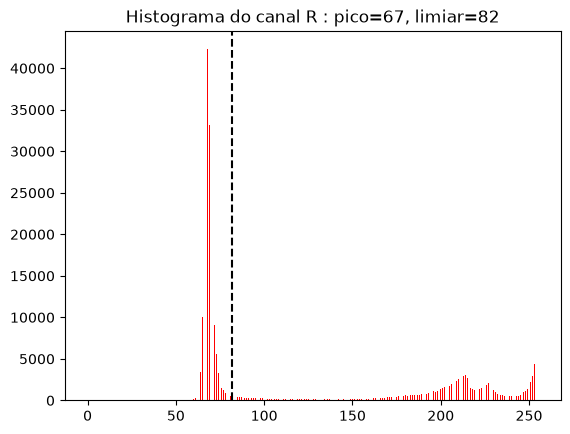

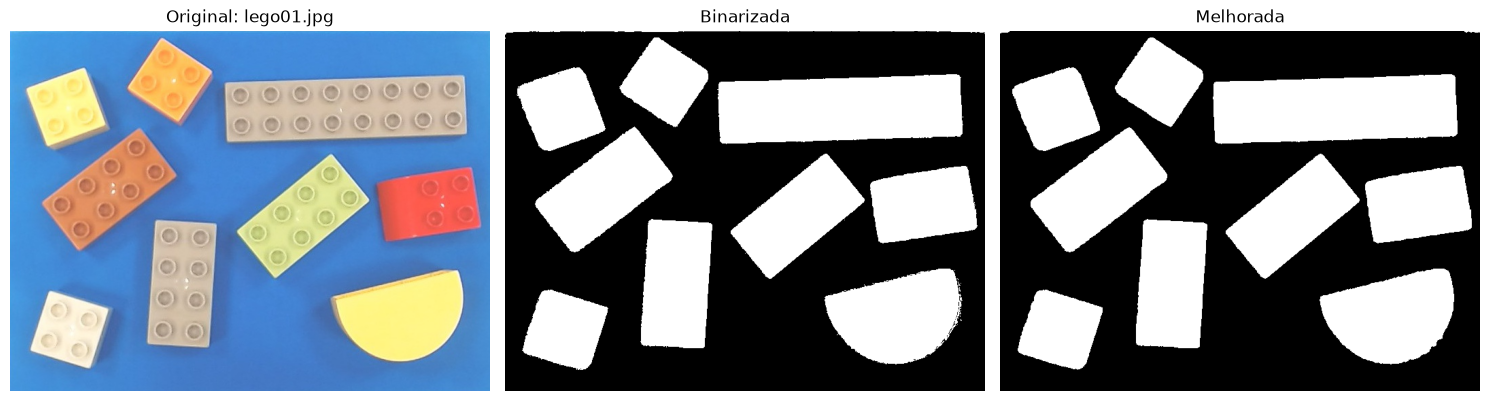

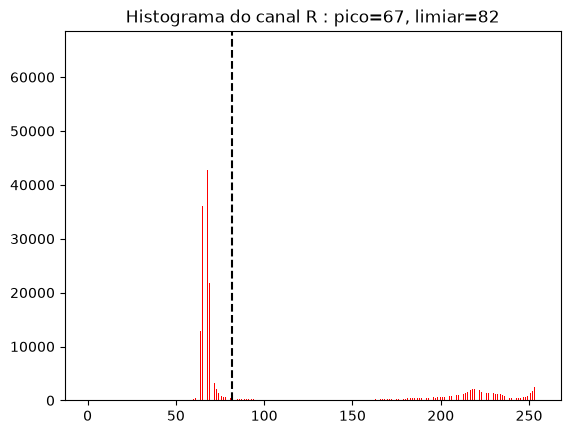

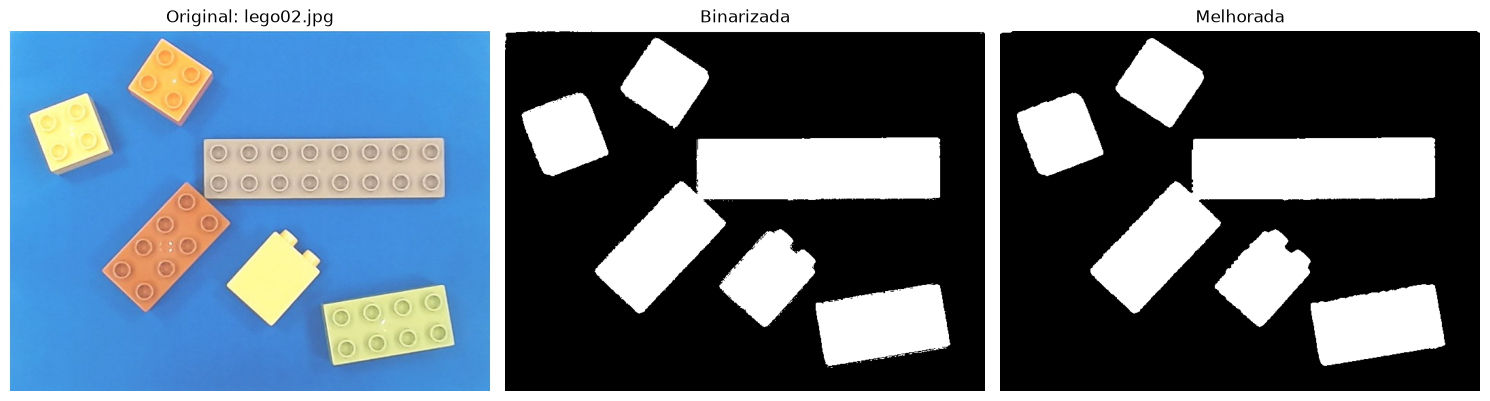

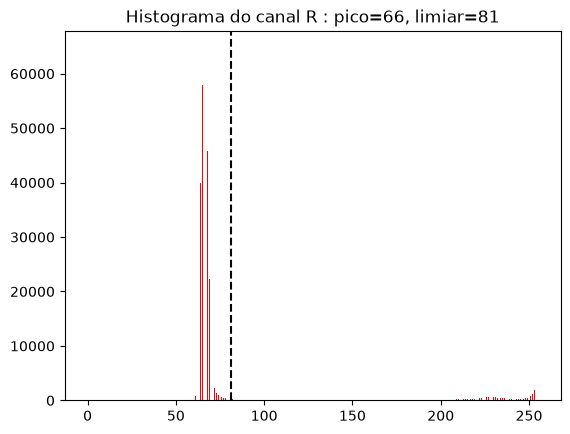

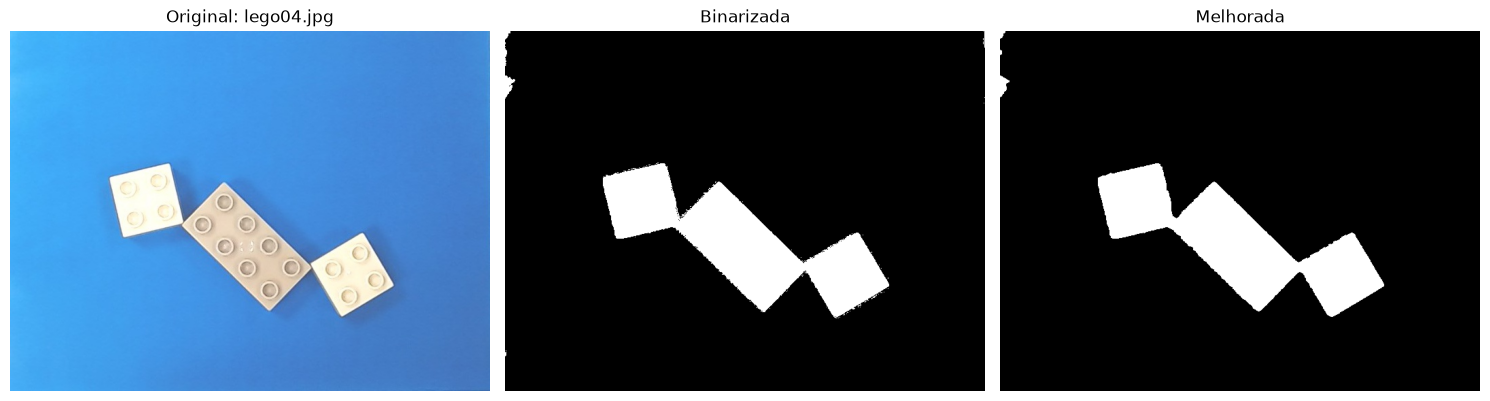

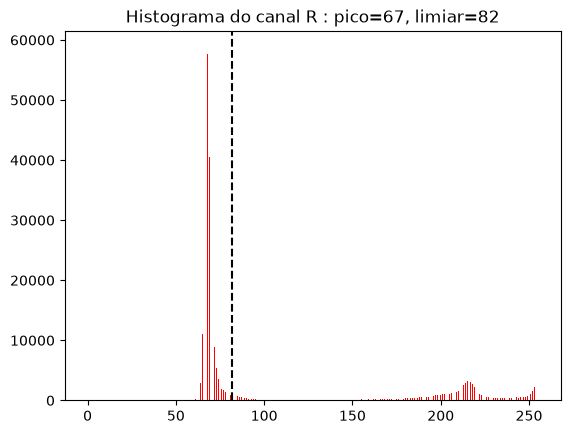

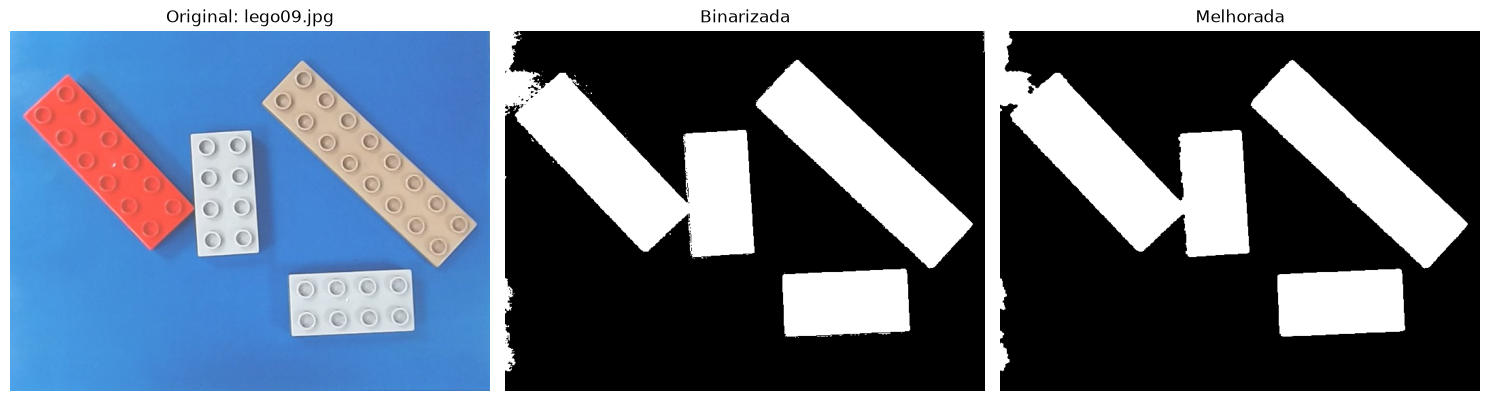

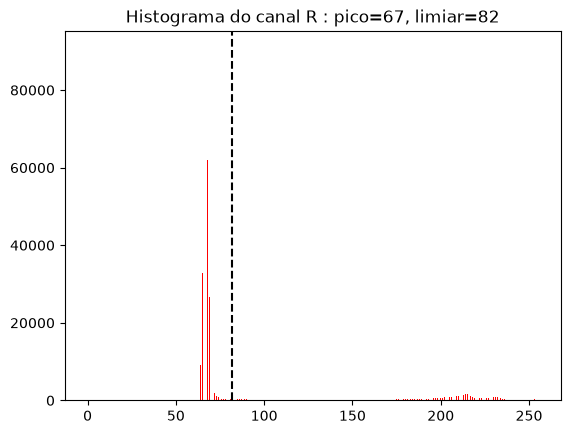

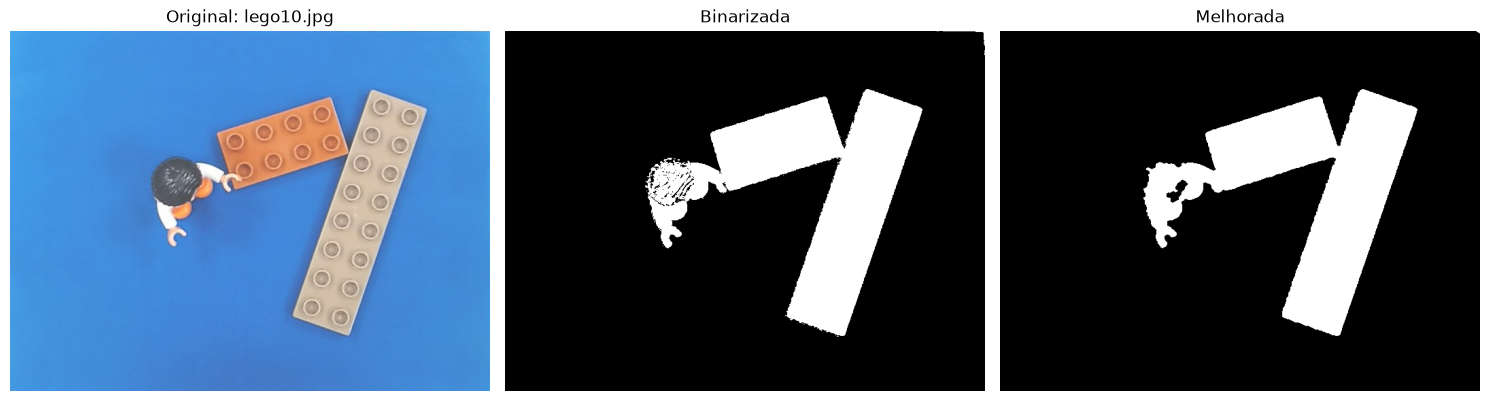

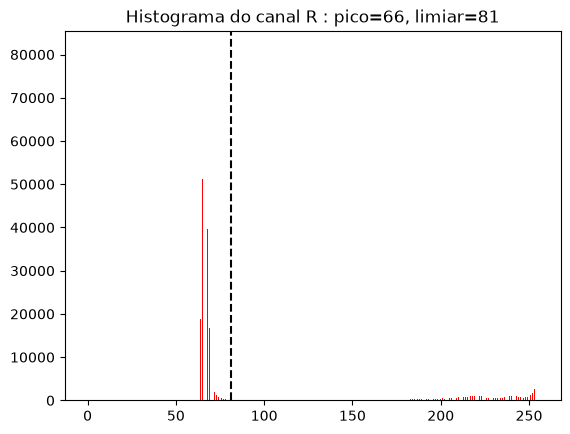

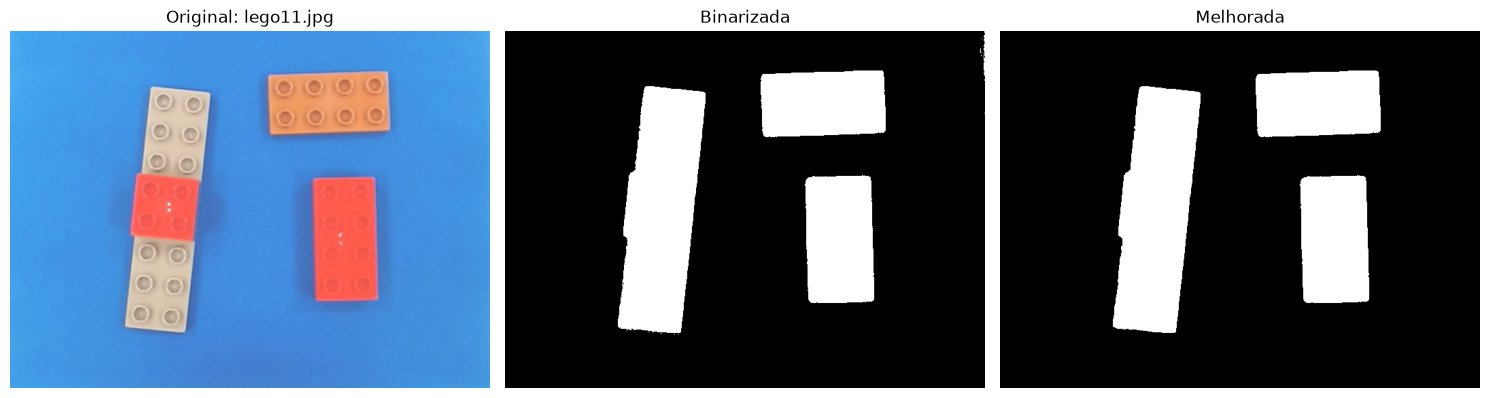

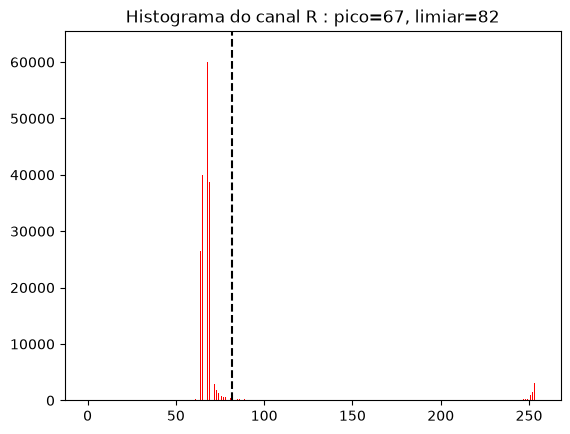

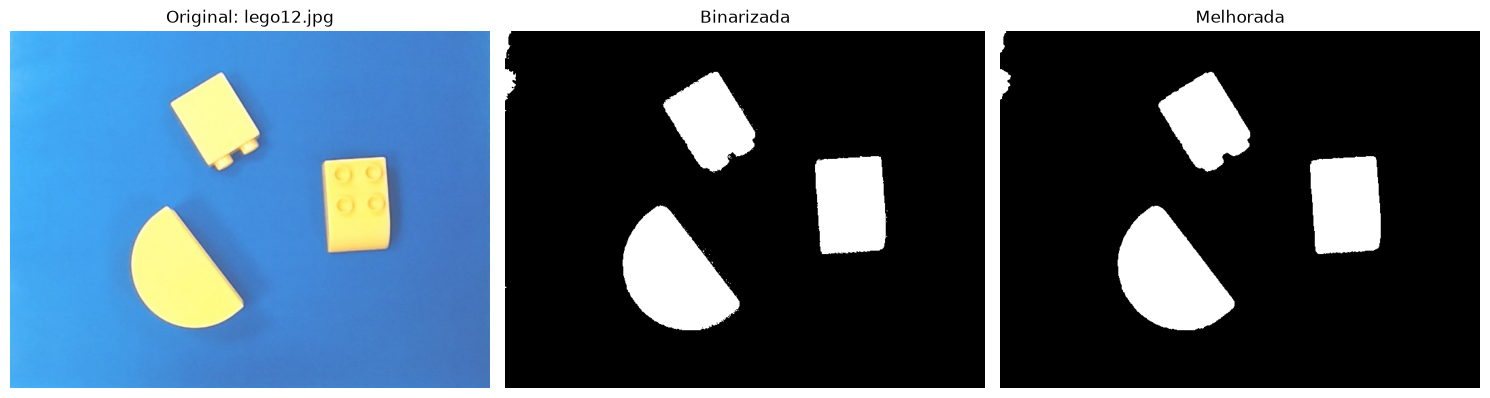

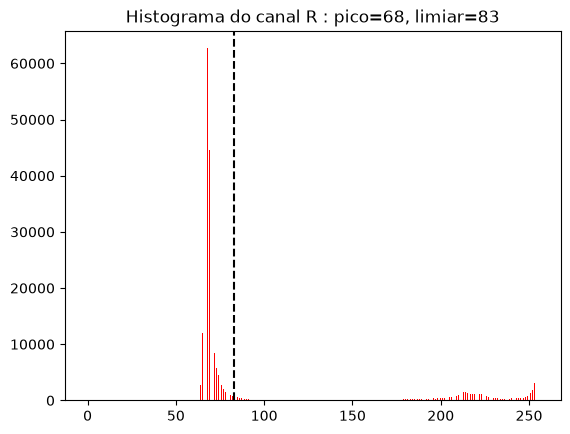

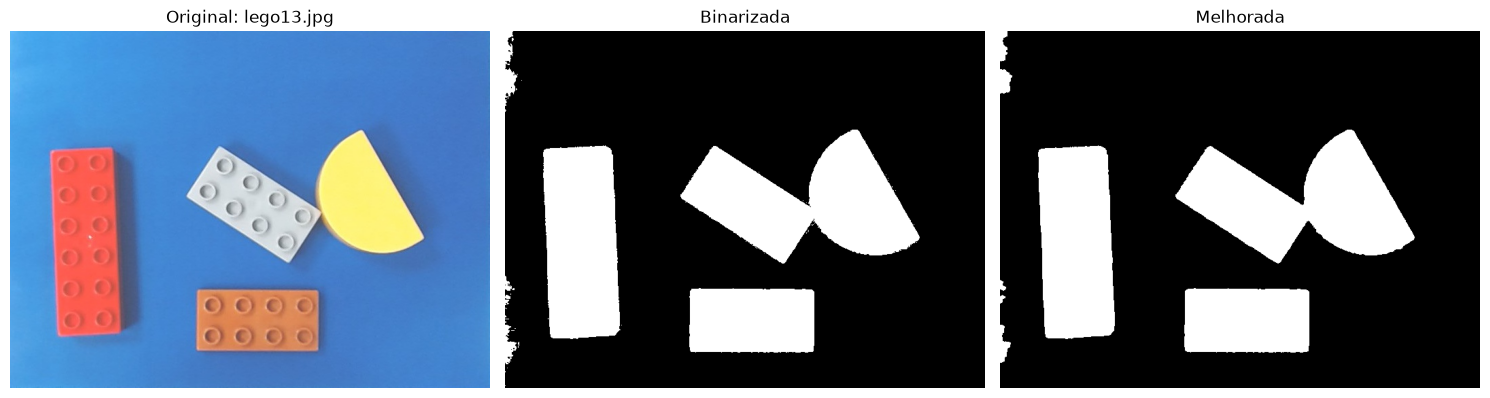

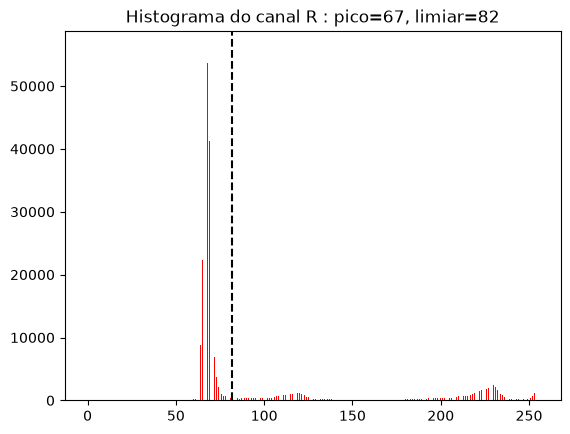

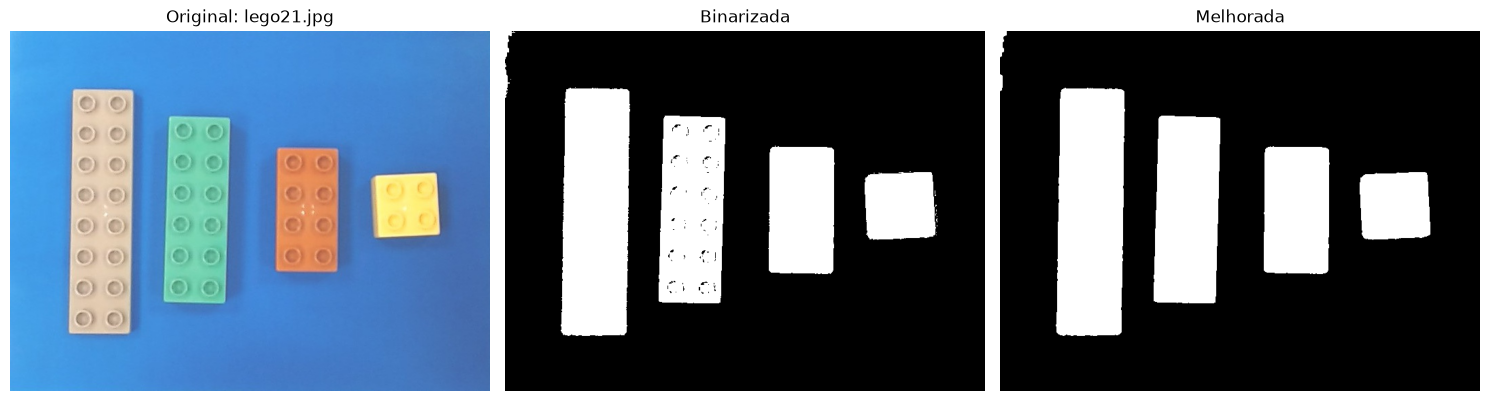

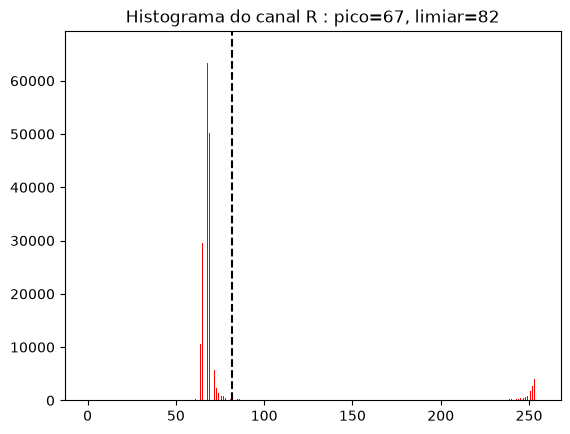

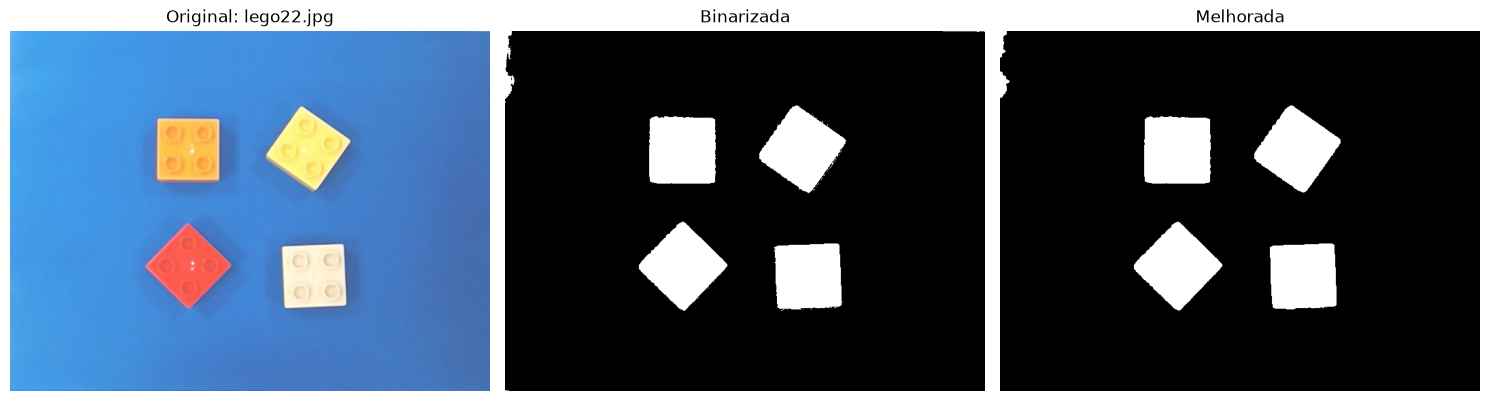

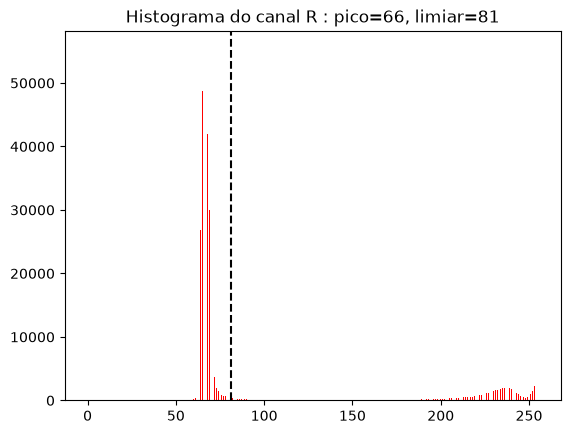

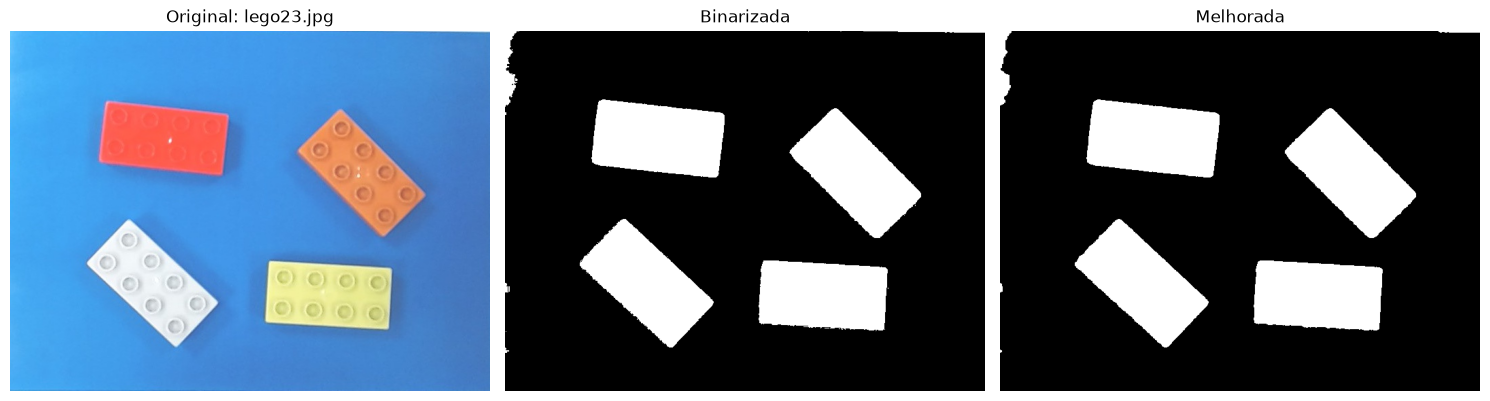

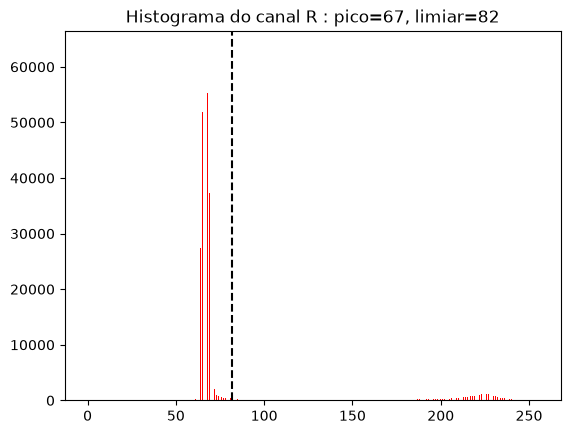

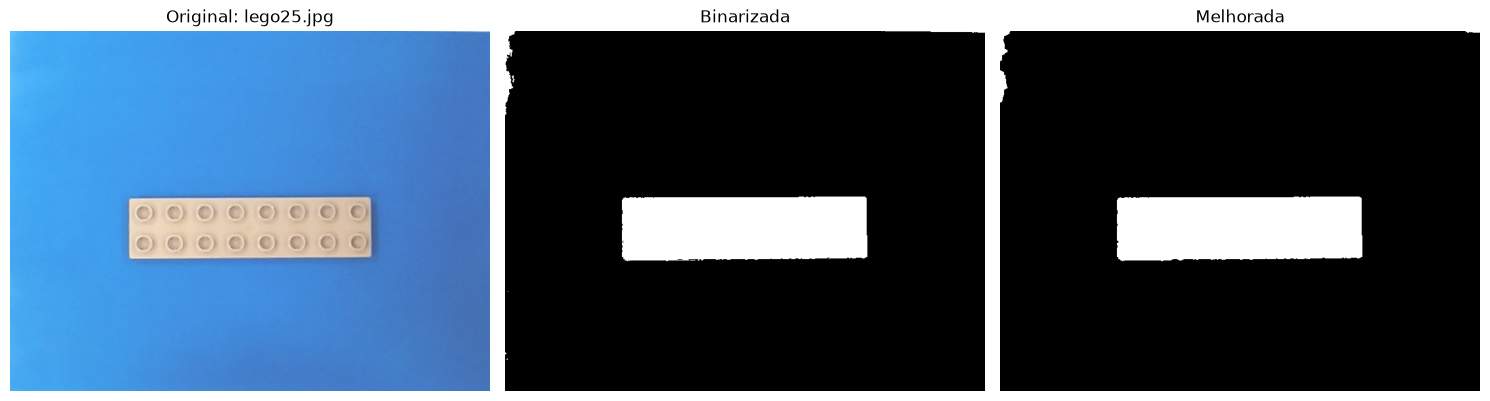

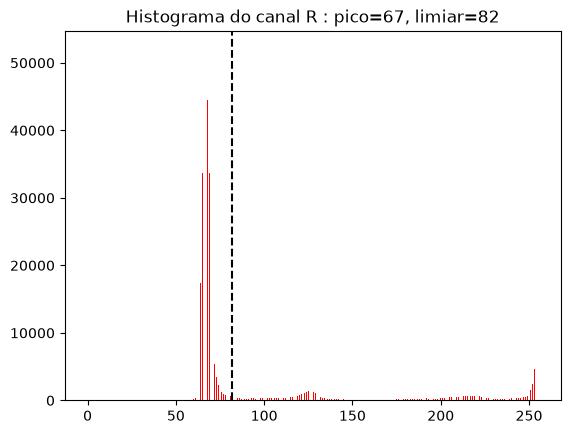

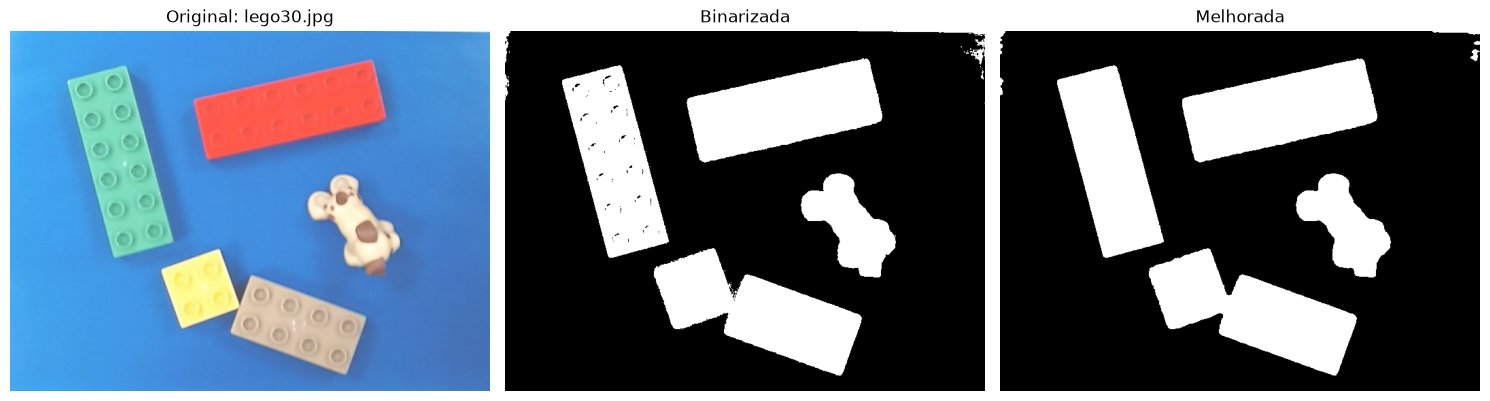

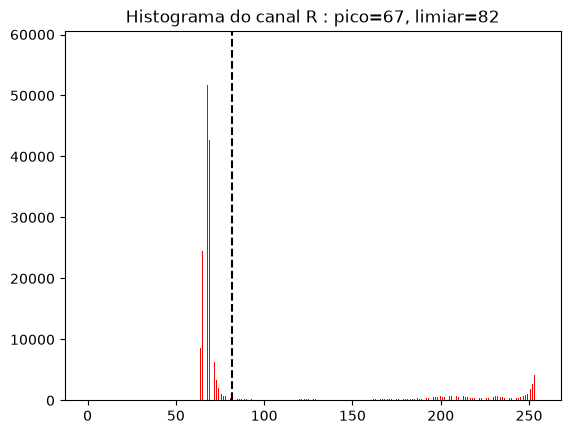

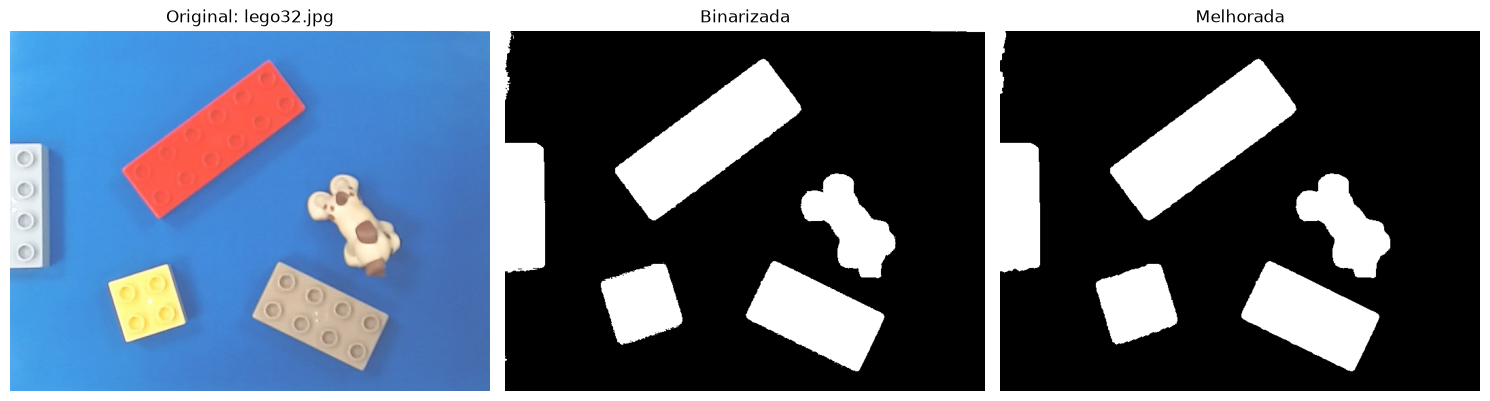

In [6]:

from pathlib import Path
import matplotlib.pyplot as plt
import cv2

# Pasta com todas as imagens de treino
pasta = Path("treino")

# Procurar todas as imagens
caminhos = sorted(
	list(pasta.glob("*.jpg")) +
	list(pasta.glob("*.jpeg")) +
	list(pasta.glob("*.png"))
)

print(f"Foram encontradas {len(caminhos)} imagens.")

# Instanciar as classes
carregador = Carregador_Imagem()
segmentador = Segmentador()

# Processar todas as imagens
for caminho in caminhos:

	imagem_original = carregador.carregar_imagem(str(caminho))

	cinzenta_analisada = segmentador.analisar_imagem(
		imagem_original
	)

	binaria = segmentador.binarizar_imagem(
		imagem_original
	)

	imagem_melhorada = segmentador.melhorar_imagem(
		binaria
	)

	# Mostrar os três resultados
	fig, eixos = plt.subplots(1, 3, figsize=(15, 5))

	eixos[0].imshow(
		cv2.cvtColor(imagem_original, cv2.COLOR_BGR2RGB)
	)
	eixos[0].set_title(f"Original: {caminho.name}")

	eixos[1].imshow(binaria, cmap="gray")
	eixos[1].set_title("Binarizada")

	eixos[2].imshow(imagem_melhorada, cmap="gray")
	eixos[2].set_title("Melhorada")

	for eixo in eixos:
		eixo.axis("off")

	plt.tight_layout()
	plt.show()


In [7]:
class DetetorObjetos:

	def detetar_objetos(self, imagem_binaria):
		# Encontrar os contornos externos dos objetos
		contornos, _ = cv2.findContours(
			imagem_binaria,
			cv2.RETR_EXTERNAL,
			cv2.CHAIN_APPROX_SIMPLE
		)

		return contornos

	def extrair_caracteristicas(self, contorno):
		# Área do objeto
		area = cv2.contourArea(contorno)

		# Retângulo que envolve o objeto
		x, y, largura, altura = cv2.boundingRect(contorno)

		# Relação entre largura e altura
		proporcao = largura / altura if altura > 0 else 0

		# Percentagem do retângulo ocupada pelo objeto
		area_retangulo = largura * altura
		extensao = area / area_retangulo if area_retangulo > 0 else 0

		return {
			"contorno": contorno,
			"x": x,
			"y": y,
			"largura": largura,
			"altura": altura,
			"area": area,
			"proporcao": proporcao,
			"extensao": extensao
		}

	def filtrar_objetos(self, objetos, area_minima):
		# Eliminar objetos com área demasiado pequena
		objetos_filtrados = []

		for objeto in objetos:
			if objeto["area"] >= area_minima:
				objetos_filtrados.append(objeto)

		return objetos_filtrados


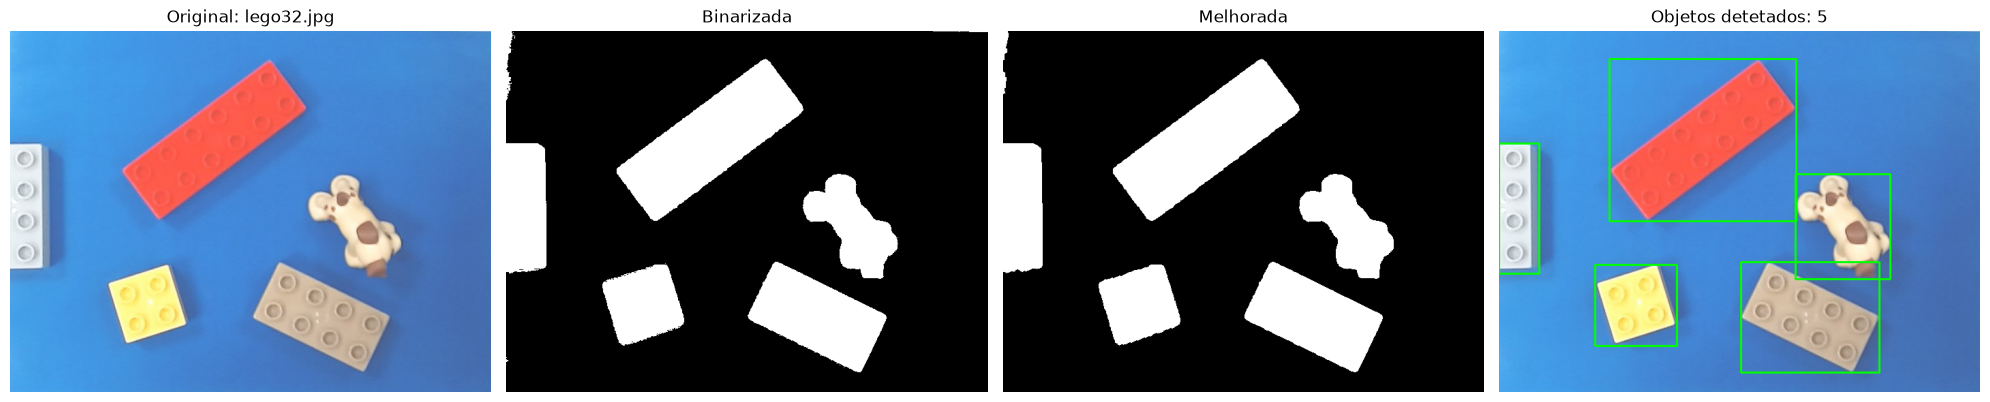

In [8]:
# 1. Detetar os contornos
detetor = DetetorObjetos()
contornos = detetor.detetar_objetos(imagem_melhorada)

# 2. Extrair as características
objetos = []

for contorno in contornos:
	objeto = detetor.extrair_caracteristicas(contorno)
	objetos.append(objeto)

# 3. Filtrar objetos pequenos
objetos_filtrados = detetor.filtrar_objetos(
	objetos,
	500
)

# 4. Desenhar os retângulos na imagem original
imagem_visualizacao = imagem_original.copy()

for objeto in objetos_filtrados:
	x = objeto["x"]
	y = objeto["y"]
	largura = objeto["largura"]
	altura = objeto["altura"]

	cv2.rectangle(
		imagem_visualizacao,
		(x, y),
		(x + largura, y + altura),
		(0, 255, 0),
		2
	)

# Mostrar os resultados
fig, eixos = plt.subplots(1, 4, figsize=(20, 5))

eixos[0].imshow(
	cv2.cvtColor(imagem_original, cv2.COLOR_BGR2RGB)
)
eixos[0].set_title(f"Original: {caminho.name}")

eixos[1].imshow(binaria, cmap="gray")
eixos[1].set_title("Binarizada")

eixos[2].imshow(imagem_melhorada, cmap="gray")
eixos[2].set_title("Melhorada")

eixos[3].imshow(
	cv2.cvtColor(imagem_visualizacao, cv2.COLOR_BGR2RGB)
)
eixos[3].set_title(
	f"Objetos detetados: {len(objetos_filtrados)}"
)

for eixo in eixos:
	eixo.axis("off")

plt.tight_layout()
plt.show()

## 6. Classificação ##

In [9]:
class ClassificadorLego:
	def distinguir_lego(self, caracterisiticas): #identificar peças potencialmente relevantes
		pass
	def classificar_peca(self, caracterisiticas): #classificar em 2x2, 2x4, 2x6 ou 2x8
		pass
	def classificar_objeto(self, objetos): #eliminar objetos irrelevates
		pass

## 7. Resultados ##

In [10]:
class Resultados:
	def contar_pecas(self, objetos_classificados): #contar cada classe
		pass
	def desenhar_resultados(self, imagem, objetos_classificados): #desenhar contornos e etiquetas\	\
		pass
	def apresentar_resultados(self, imagem, contagens): #mostrar os totais
		pass
	def avaliar_resultados(): #comparar previsoes com contagens corretas
		pass

## 8. Conclusões ##

## 9. Referências ##